In [1]:
import numpy as np, pandas as pd, os
rng = np.random.default_rng(42)
n = 5000

reliability = rng.normal(0, 1, n)                 # hidden trait: NOT given to the model
tenure = rng.integers(1, 61, n)
on_time = np.clip(0.75 + 0.12*reliability + rng.normal(0, 0.08, n), 0.2, 1.0)
loans_total = rng.poisson(1 + tenure/24)
p_late = np.clip(0.2 - 0.07*reliability, 0.02, 0.8)
loans_late = rng.binomial(loans_total, p_late)
loans_ontime = loans_total - loans_late

savings = rng.lognormal(12.5, 0.6, n)             # UGX
loan_amt = savings * rng.uniform(0.5, 3.0, n)
loan_to_savings = loan_amt / savings
guarantor = rng.choice([0, 0.25, 0.5, 1.0], p=[.4, .2, .2, .2], size=n)

logit = (-1.0 - 0.8*reliability + 0.7*(loan_to_savings - 1.5)
         - 0.9*guarantor - 0.015*tenure + 0.5*loans_late)
defaulted = rng.binomial(1, 1/(1 + np.exp(-logit)))

df = pd.DataFrame({
    "on_time_rate": on_time.round(3),
    "tenure_months": tenure,
    "past_loans_on_time": loans_ontime,
    "past_loans_late": loans_late,
    "loan_to_savings": loan_to_savings.round(2),
    "guarantor_cover": guarantor,
    "defaulted": defaulted,
    # audit-only columns: NEVER used for training (NFR-19)
    "gender": rng.choice(["F", "M"], n),
    "region": rng.choice(["Central", "Eastern", "Northern", "Western"], n),
})
df.loc[rng.choice(n, 75, replace=False), "on_time_rate"] = np.nan   # realistic missing data

os.makedirs("data", exist_ok=True)
df.to_csv("data/chama_loans.csv", index=False)
print(df.shape, "default rate:", df.defaulted.mean().round(3))

(5000, 9) default rate: 0.257


,on_time_rate,tenure_months,past_loans_on_time,past_loans_late,loan_to_savings,guarantor_cover,defaulted,gender,region
0,0.612,34,2,1,1.44,0.5,0,M,Northern
1,NaN,19,2,0,2.13,0.5,0,F,Western
2,0.849,7,2,1,1.91,0.0,0,M,Northern
3,NaN,26,2,0,2.91,0.0,0,F,Eastern
4,0.610,16,1,0,1.75,0.5,0,M,Eastern


<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   on_time_rate        4925 non-null   float64
 1   tenure_months       5000 non-null   int64  
 2   past_loans_on_time  5000 non-null   int64  
 3   past_loans_late     5000 non-null   int64  
 4   loan_to_savings     5000 non-null   float64
 5   guarantor_cover     5000 non-null   float64
 6   defaulted           5000 non-null   int64  
 7   gender              5000 non-null   str    
 8   region              5000 non-null   str    
dtypes: float64(3), int64(4), str(2)
memory usage: 351.7 KB
       on_time_rate  tenure_months  past_loans_on_time  past_loans_late  \
count   4925.000000    5000.000000         5000.000000      5000.000000   
mean       0.743654      30.270600            1.818200         0.452800   
std        0.137665      17.322996            1.478779         0.705033   
min   

Matplotlib is building the font cache; this may take a moment.


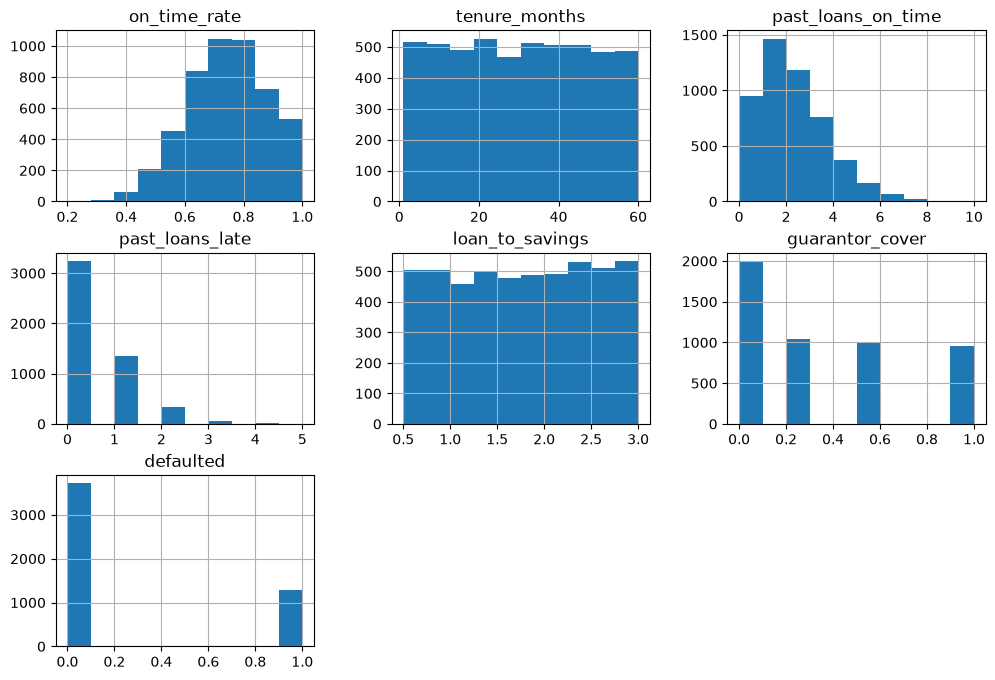

In [2]:
df = pd.read_csv("data/chama_loans.csv")
display(df.head())
df.info()
print(df.describe())
print(df.isna().sum())
df.hist(figsize=(12, 8));

In [9]:
from sklearn.model_selection import train_test_split
FEATURES = [
    "on_time_rate",
    "tenure_months",
    "past_loans_on_time",
    "past_loans_late",
    "loan_to_savings",
    "guarantor_cover",
]

X, y = df[FEATURES], df["defaulted"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

In [10]:
from sklearn.metrics import roc_auc_score

def scorecard(d):
    pts = (50 + (d.on_time_rate - 0.75)*100 + d.tenure_months.clip(upper=36)*0.3
           + d.past_loans_on_time*2 - d.past_loans_late*8
           - (d.loan_to_savings - 1.5)*10 + d.guarantor_cover*10)
    return pts.clip(0, 100)

X_te_f = X_te.fillna(X_tr.median())
print("Baseline AUC:", roc_auc_score(y_te, 100 - scorecard(X_te_f)))

Baseline AUC: 0.7092055029824406


In [11]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

model = make_pipeline(SimpleImputer(strategy="median"),
                      StandardScaler(),
                      LogisticRegression(max_iter=1000))
model.fit(X_tr, y_tr)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('simpleimputer', ...), ('standardscaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['on_time_rate','tenure_months','past_loans_on_time','past_loans_late', 'loan_to_savings','guarantor_cover']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace allo

Model AUC: 0.7153301108661384
5-fold CV AUC: 0.7542599837229538
              precision    recall  f1-score   support

           0       0.84      0.74      0.78       743
           1       0.44      0.59      0.50       257

    accuracy                           0.70      1000
   macro avg       0.64      0.66      0.64      1000
weighted avg       0.73      0.70      0.71      1000



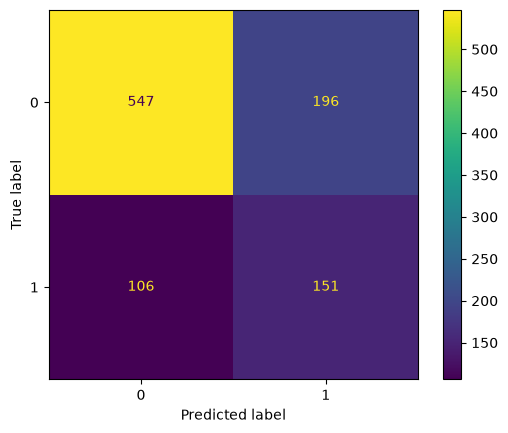

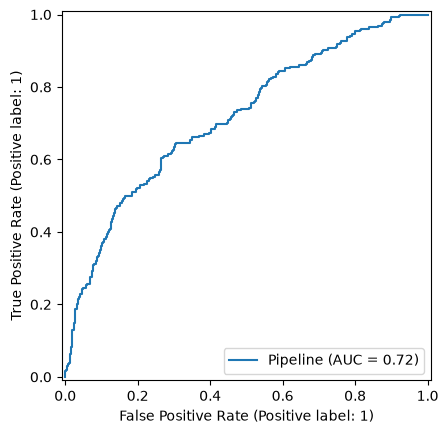

In [12]:
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay,
                             RocCurveDisplay)
from sklearn.model_selection import cross_val_score

proba = model.predict_proba(X_te)[:, 1]
print("Model AUC:", roc_auc_score(y_te, proba))
print("5-fold CV AUC:", cross_val_score(model, X, y, cv=5, scoring="roc_auc").mean())
pred = (proba >= 0.30).astype(int)          # flag "high risk" at 30%
print(classification_report(y_te, pred))
ConfusionMatrixDisplay.from_predictions(y_te, pred)
RocCurveDisplay.from_estimator(model, X_te, y_te)

In [13]:
from sklearn.ensemble import HistGradientBoostingClassifier
gb = HistGradientBoostingClassifier(random_state=42).fit(X_tr, y_tr)
print("Gradient boosting AUC:", roc_auc_score(y_te, gb.predict_proba(X_te)[:, 1]))

Gradient boosting AUC: 0.6973726243905505


In [16]:
# scoring.py
import pandas as pd

def score_with_reasons(model, X):
    """
    Return risk probability and a short list of reasons for one row.
    Works with sklearn Pipeline objects like:
        SimpleImputer -> StandardScaler -> LogisticRegression
    """
    if not isinstance(X, pd.DataFrame):
        raise TypeError("X must be a pandas DataFrame")

    if X.empty:
        return {"score": 0.0, "risk_probability": 0.0, "reasons": []}

    row = X.iloc[[0]].copy()
    prob = float(model.predict_proba(row)[0, 1])
    score = round(prob * 100, 1)

    reasons = []
    try:
        lr = model.named_steps["logisticregression"]
        feature_names = list(model.feature_names_in_)
        coefs = lr.coef_[0]

        for name, coef in zip(feature_names, coefs):
            value = float(row[name].iloc[0])
            if abs(coef) < 1e-12:
                continue
            if coef > 0:
                reasons.append(f"{name}={value:.3f} raises default risk")
            else:
                reasons.append(f"{name}={value:.3f} reduces default risk")
    except Exception:
        reasons = ["Model score computed successfully"]

    return {
        "score": score,
        "risk_probability": round(prob, 4),
        "reasons": reasons[:5],
    }
print(score_with_reasons(model, X_te.iloc[[0]]))

{'score': 35.2, 'risk_probability': 0.3518, 'reasons': ['on_time_rate=0.888 reduces default risk', 'tenure_months=20.000 reduces default risk', 'past_loans_on_time=0.000 reduces default risk', 'past_loans_late=1.000 raises default risk', 'loan_to_savings=2.570 raises default risk']}


In [17]:
audit = df.loc[X_te.index, ["gender", "region"]].assign(
    score=(1 - proba) * 100, defaulted=y_te, flagged=pred)
for col in ["gender", "region"]:
    print(audit.groupby(col).agg(avg_score=("score", "mean"),
          actual_default=("defaulted", "mean"), flagged=("flagged", "mean")).round(3))

        avg_score  actual_default  flagged
gender                                    
F          73.595           0.237    0.347
M          74.561           0.279    0.347
          avg_score  actual_default  flagged
region                                      
Central      73.432           0.266    0.365
Eastern      75.321           0.238    0.321
Northern     73.543           0.255    0.332
Western      73.910           0.269    0.369


In [18]:
import joblib
joblib.dump(model, "models/risk_v1.joblib")


['models/risk_v1.joblib']